Using NBA shot data, how does the game situation affect the field goal percentage (make or miss) of shots?

Questions: Do home teams shoot better? Do end-of-quarter shots drop off? Did pandemic seasons (2019–20 bubble, 2020–21 empty arenas) change home advantage?

Columns: QUARTER, SECONDS_LEFT_IN_PERIOD, IS_HOME, SEASON

Notes:
- There are five data points with 12 minutes left (doesn't make sense)
- Create a new feature that has the team name abbreviated (to make it consistent with the HOME_TEAM and AWAY_TEAM values)

In [1]:
import matplotlib.pyplot as plt 
import numpy as np
import pandas as pd

df = pd.read_csv("datasets/train_with_player_bio.csv")
# change data points with 12 minutes left to 11 minutes left (5 data points)
df["MINS_LEFT"] = df["MINS_LEFT"].replace(12, 11)

print(df.head())

   SEASON_1 SEASON_2     TEAM_ID      TEAM_NAME  PLAYER_ID        PLAYER_NAME  \
0      2022  2021-22  1610612737  Atlanta Hawks    1628381       John Collins   
1      2022  2021-22  1610612737  Atlanta Hawks    1629631    De'Andre Hunter   
2      2022  2021-22  1610612737  Atlanta Hawks    1629027         Trae Young   
3      2022  2021-22  1610612737  Atlanta Hawks    1628381       John Collins   
4      2022  2021-22  1610612737  Atlanta Hawks     203992  Bogdan Bogdanović   

  POSITION_GROUP POSITION   GAME_DATE   GAME_ID  ... IS_THREE PLAYER_HEIGHT  \
0              F      F-C  10-21-2021  22100014  ...        0           6-9   
1              F      F-G  10-21-2021  22100014  ...        0           6-8   
2              G        G  10-21-2021  22100014  ...        0           6-1   
3              F      F-C  10-21-2021  22100014  ...        0           6-9   
4              G        G  10-21-2021  22100014  ...        1           6-6   

  PLAYER_HEIGHT_INCHES  PLAYER_WEIGHT 

# Field Goal % by Season, Quarter, and Minutes Left

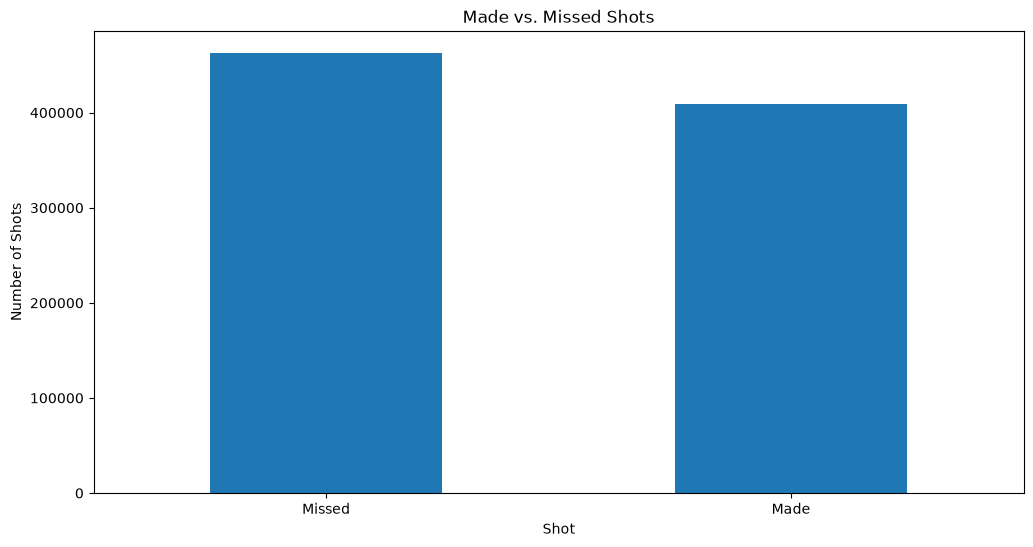

MADE
Missed    462674.00
Made      409495.00
Total     872169.00
FG%           46.95
dtype: float64

In [32]:
fg_stats = df.groupby(["MADE"]).size()
fg_stats = fg_stats.rename(index={0: "Missed", 1: "Made"})

fg_stats.plot(kind="bar", figsize=(12, 6))

plt.xticks(rotation=0)
plt.xticks([0, 1], ["Missed", "Made"])
plt.xlabel("Shot")
plt.ylabel("Number of Shots")
plt.title("Made vs. Missed Shots")
plt.show()

fg_stats["Total"] = fg_stats["Made"] + fg_stats["Missed"]

fg_stats["FG%"] = (fg_stats["Made"] / (fg_stats["Made"] + fg_stats["Missed"])) * 100

display(fg_stats.round(2))

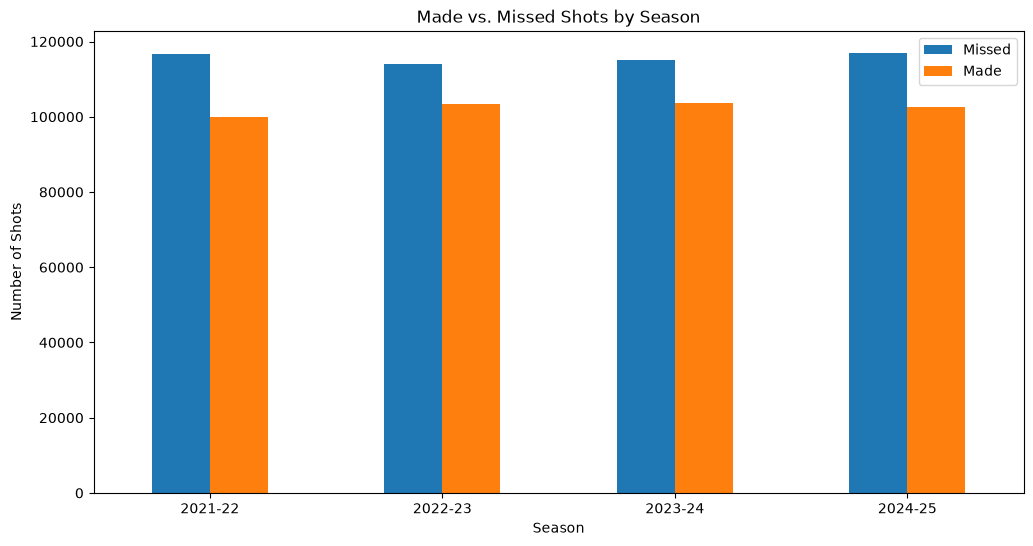

,Missed,Made,Total,FG%
SEASON,,,,
2021-22,116792,99930,216722,46.11
2022-23,113960,103260,217220,47.54
2023-24,114961,103739,218700,47.43
2024-25,116961,102566,219527,46.72


In [2]:
# group shots by season and count made/missed
season_stats = df.groupby(["SEASON", "MADE"]).size().unstack(fill_value=0)

season_stats.columns = ["Missed", "Made"]
season_stats.plot(kind="bar", figsize=(12, 6))

plt.xticks(rotation=0)
plt.xlabel("Season")
plt.ylabel("Number of Shots")
plt.title("Made vs. Missed Shots by Season")
plt.show()

season_stats["Total"] = season_stats["Made"] + season_stats["Missed"]

season_stats["FG%"] = (season_stats["Made"] / (season_stats["Made"] + season_stats["Missed"])) * 100

display(season_stats.round(2))

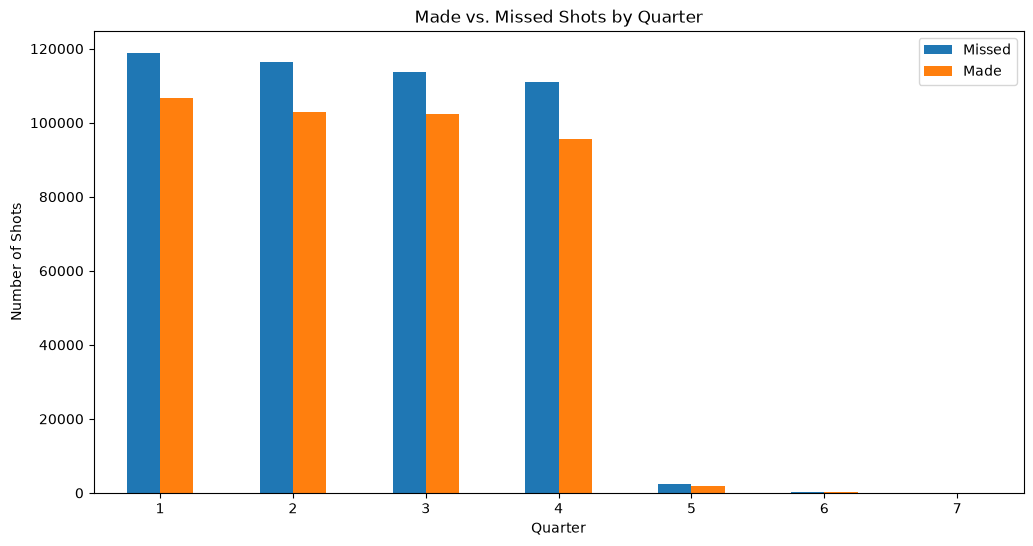

,Missed,Made,Total,FG%
QUARTER,,,,
1,118850,106612,225462,47.29
2,116311,102803,219114,46.92
3,113663,102476,216139,47.41
4,111020,95527,206547,46.25
5,2512,1867,4379,42.64
6,302,196,498,39.36
7,16,14,30,46.67


In [3]:
# group shots by quarter
quarter_stats = df.groupby(["QUARTER", "MADE"]).size().unstack(fill_value=0)
quarter_stats.columns = ["Missed", "Made"]

quarter_stats.plot(kind="bar", figsize=(12, 6))

plt.xticks(rotation=0)
plt.xlabel("Quarter")
plt.ylabel("Number of Shots")
plt.title("Made vs. Missed Shots by Quarter")
plt.show()

quarter_stats["Total"] = quarter_stats["Made"] + quarter_stats["Missed"]

quarter_stats["FG%"] = (quarter_stats["Made"] / (quarter_stats["Made"] + quarter_stats["Missed"])) * 100

display (quarter_stats.round(2))

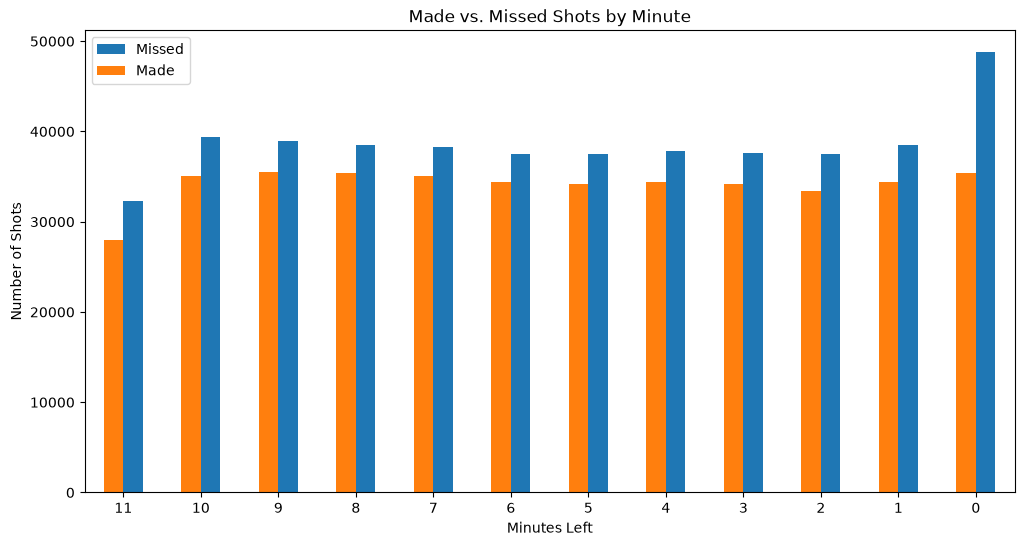

,Missed,Made,Total,FG%
MINS_LEFT,,,,
11,32257,27964,60221,46.44
10,39381,35059,74440,47.10
9,38995,35564,74559,47.70
8,38557,35434,73991,47.89
7,38249,35086,73335,47.84
6,37530,34393,71923,47.82
5,37500,34206,71706,47.70
4,37888,34369,72257,47.56
3,37651,34137,71788,47.55


In [4]:
# group shots by minute
minute_stats = df.groupby(["MINS_LEFT", "MADE"]).size().unstack(fill_value=0)

minute_stats.columns = ["Missed", "Made"]

minute_stats.plot(kind="bar", figsize=(12, 6))
# reverse row values for the table
minute_stats = minute_stats.sort_values(["MINS_LEFT"], ascending=[False])

plt.xticks(rotation=0)
# reverse x axis order
plt.gca().invert_xaxis()
plt.xlabel("Minutes Left")
plt.ylabel("Number of Shots")
plt.title("Made vs. Missed Shots by Minute")
plt.show()

minute_stats["Total"] = minute_stats["Made"] + minute_stats["Missed"]

minute_stats["FG%"] = (minute_stats["Made"] / (minute_stats["Made"] + minute_stats["Missed"])) * 100

display(minute_stats.round(2))

# Three Point % by Season, Quarter, and Minutes Left

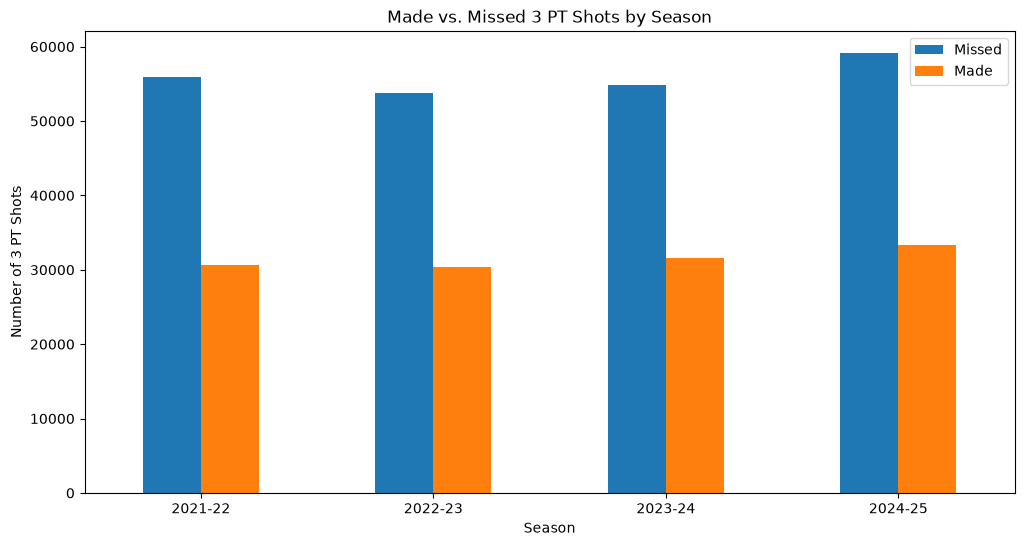

,Missed,Made,Total,3FG%
SEASON,,,,
2021-22,55937,30598,86535,35.36
2022-23,53805,30359,84164,36.07
2023-24,54776,31579,86355,36.57
2024-25,59150,33304,92454,36.02


In [5]:
three_season_stats = df[df["IS_THREE"] == 1].groupby(["SEASON", "MADE"]).size().unstack(fill_value=0)
three_season_stats.columns = ["Missed", "Made"]

three_season_stats.plot(kind="bar", figsize=(12, 6))

plt.xticks(rotation=0)
plt.xlabel("Season")
plt.ylabel("Number of 3 PT Shots")
plt.title("Made vs. Missed 3 PT Shots by Season")
plt.show()

three_season_stats["Total"] = three_season_stats["Made"] + three_season_stats["Missed"]

three_season_stats["3FG%"] = (three_season_stats["Made"] / (three_season_stats["Made"] + three_season_stats["Missed"])) * 100

display (three_season_stats.round(2))

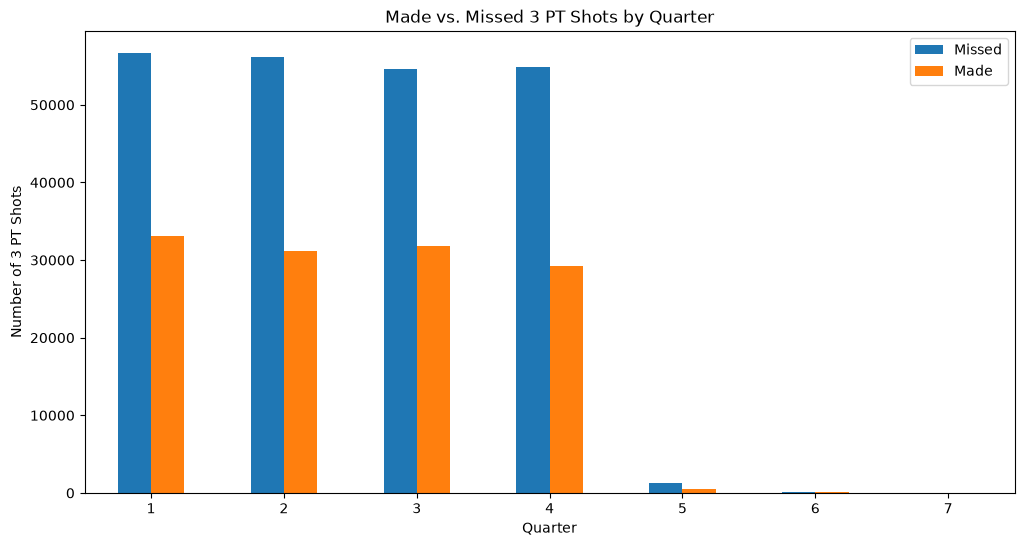

,Missed,Made,Total,3FG%
QUARTER,,,,
1,56684,33124,89808,36.88
2,56174,31119,87293,35.65
3,54561,31829,86390,36.84
4,54874,29189,84063,34.72
5,1219,516,1735,29.74
6,147,58,205,28.29
7,9,5,14,35.71


In [6]:
three_quarter_stats = df[df["IS_THREE"] == 1].groupby(["QUARTER", "MADE"]).size().unstack(fill_value=0)
three_quarter_stats.columns = ["Missed", "Made"]

three_quarter_stats.plot(kind="bar", figsize=(12, 6))

plt.xticks(rotation=0)
plt.xlabel("Quarter")
plt.ylabel("Number of 3 PT Shots")
plt.title("Made vs. Missed 3 PT Shots by Quarter")
plt.show()

three_quarter_stats["Total"] = three_quarter_stats["Made"] + three_quarter_stats["Missed"]

three_quarter_stats["3FG%"] = (three_quarter_stats["Made"] / (three_quarter_stats["Made"] + three_quarter_stats["Missed"])) * 100

display (three_quarter_stats.round(2))

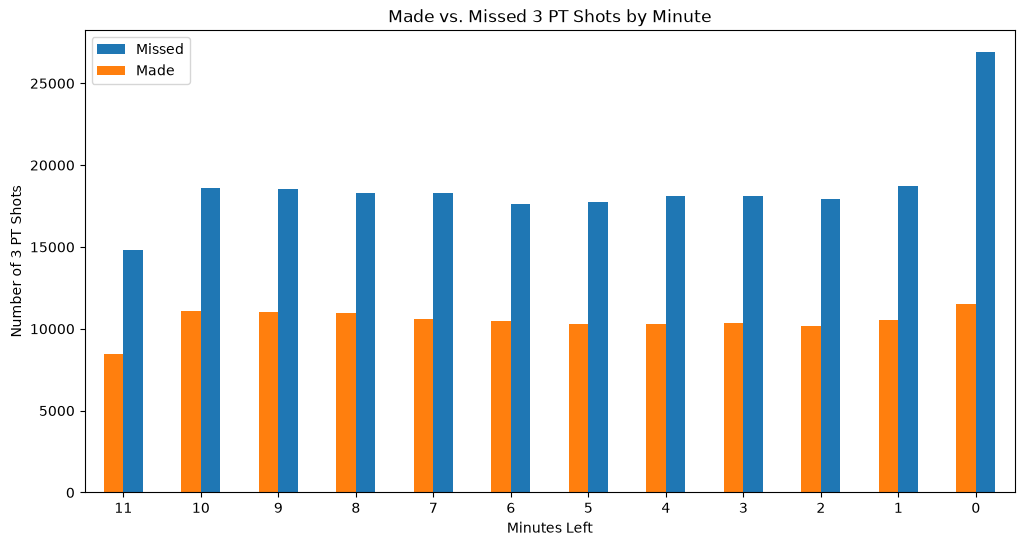

,Missed,Made,Total,3FG%
MINS_LEFT,,,,
11,14813,8450,23263,36.32
10,18579,11086,29665,37.37
9,18544,11055,29599,37.35
8,18272,10960,29232,37.49
7,18282,10630,28912,36.77
6,17641,10468,28109,37.24
5,17777,10312,28089,36.71
4,18087,10289,28376,36.26
3,18121,10335,28456,36.32


In [7]:
three_minute_stats = df[df["IS_THREE"] == 1].groupby(["MINS_LEFT", "MADE"]).size().unstack(fill_value=0)
three_minute_stats.columns = ["Missed", "Made"]

three_minute_stats.plot(kind="bar", figsize=(12, 6))
# reverse row values for the table
three_minute_stats = three_minute_stats.sort_values(["MINS_LEFT"], ascending=[False])
    
plt.xticks(rotation=0)
# reverse x axis order
plt.gca().invert_xaxis()
plt.xlabel("Minutes Left")
plt.ylabel("Number of 3 PT Shots")
plt.title("Made vs. Missed 3 PT Shots by Minute")
plt.show()

three_minute_stats["Total"] = three_minute_stats["Made"] + three_minute_stats["Missed"]

three_minute_stats["3FG%"] = (three_minute_stats["Made"] / (three_minute_stats["Made"] + three_minute_stats["Missed"])) * 100

display (three_minute_stats.round(2))

## Field Goal Percentage by Minutes Left and Quarter

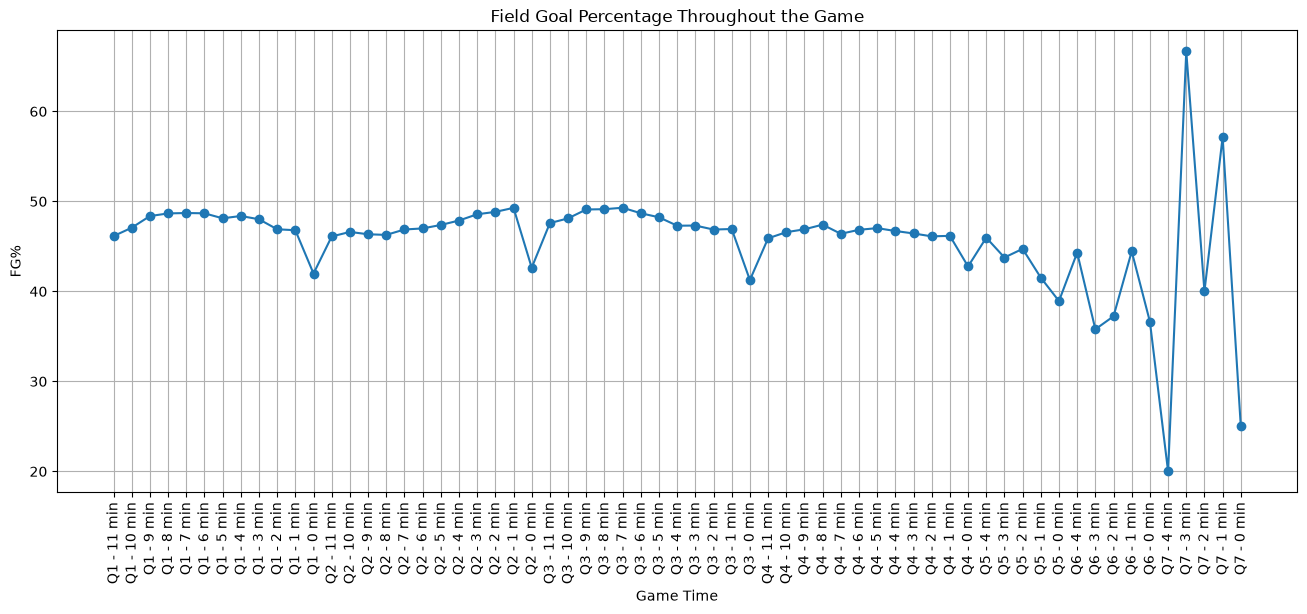

,Missed,Made,Total,FG%
Q1 - 11 min,8146,6979,15125,46.14
Q1 - 10 min,10297,9158,19455,47.07
Q1 - 9 min,10116,9476,19592,48.37
Q1 - 8 min,10024,9502,19526,48.66
Q1 - 7 min,9884,9386,19270,48.71
Q1 - 6 min,9670,9171,18841,48.68
Q1 - 5 min,9765,9057,18822,48.12
Q1 - 4 min,9594,8991,18585,48.38
Q1 - 3 min,9619,8884,18503,48.01
Q1 - 2 min,9585,8466,18051,46.90


In [8]:
time_stats = df.groupby(["QUARTER", "MINS_LEFT", "MADE"]).size().unstack(fill_value=0)
time_stats.columns = ["Missed", "Made"]

time_stats["Total"] = time_stats["Made"] + time_stats["Missed"]

time_stats["FG%"] = (time_stats["Made"] / time_stats["Total"]) * 100
# reverse row values for the table
time_stats = time_stats.sort_values(["QUARTER", "MINS_LEFT"], ascending=[True, False])

# rename rows to Quarter-Minutes left
time_stats.index = [
    f"Q{quarter} - {minute} min"
    for quarter, minute in time_stats.index
]

time_stats["FG%"].plot(
    kind="line",
    figsize=(16, 6),
    marker="o"
)

plt.xticks(rotation=90, ticks=range(len(time_stats)), labels=time_stats.index,)
plt.xlabel("Game Time")
plt.ylabel("FG%")
plt.title("Field Goal Percentage Throughout the Game")
plt.grid()
plt.show()

# show all rows
pd.set_option("display.max_rows", None)
display(time_stats.round(2))

Is FG% affected by the season? - No

Is FG% affected by the quarter? - In the fourth quarter, teams tend to shoot worse in both fg% and 3PT%. The second quarter faces a similar dropoff, but it is not as severe. The first and third quarters are the best shooting quarters probably because the players are rested coming into the game and out of halftime respectively. By the fourth quarter players are tired and shoot worse as a result. So fg% is affected by quarter, although not by a huge margin.

Is FG% affected by minute? - Players tend to start cold since the fg% in the first minute is lower than in the rest of the other minutes, but the difference is less than a percentage point. What is significant is that both the fg% and 3PT% dips 5% in the last minute. The number of shots also go up, so it could be explained by players shooting whatever shot they can before the clock expires. 

Both quarter and minutes left could contribute to fg%, it is worth testing out in our model.

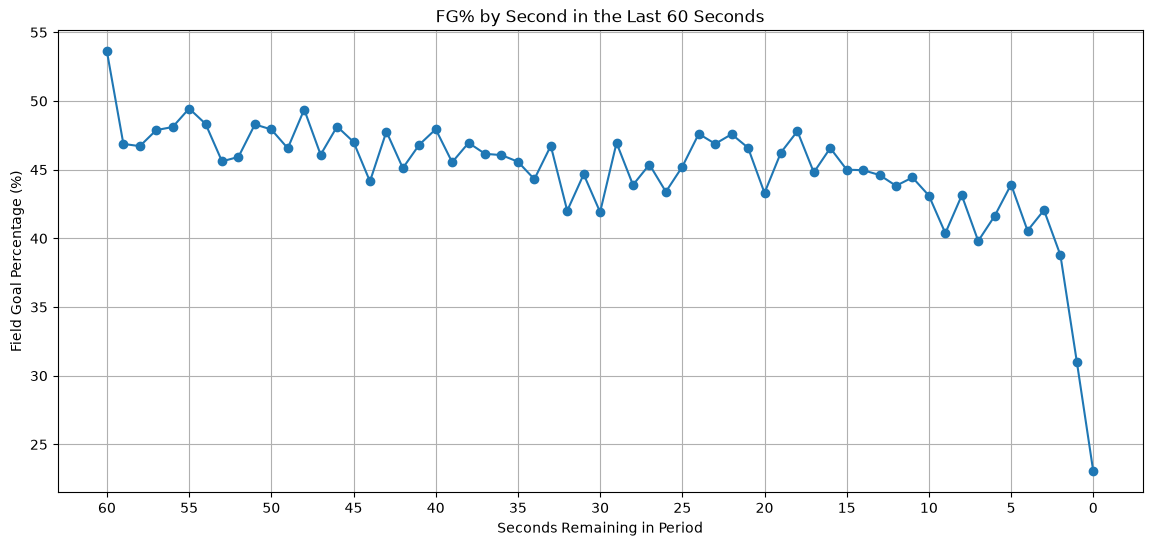

,Missed,Made,Total,FG%
SECONDS_LEFT_IN_PERIOD,,,,
60,708,818,1526,53.60
59,740,653,1393,46.88
58,697,611,1308,46.71
57,615,565,1180,47.88
56,644,597,1241,48.11
55,601,588,1189,49.45
54,636,595,1231,48.33
53,656,550,1206,45.61
52,684,581,1265,45.93


In [23]:
last_60 = df[df["SECONDS_LEFT_IN_PERIOD"] <= 60]

second_stats = last_60.groupby(["SECONDS_LEFT_IN_PERIOD", "MADE"]).size().unstack(fill_value=0)
second_stats.columns = ["Missed", "Made"]

second_stats["Total"] = second_stats["Missed"] + second_stats["Made"]
second_stats["FG%"] = second_stats["Made"] / second_stats["Total"] * 100

second_stats = second_stats.sort_values(["SECONDS_LEFT_IN_PERIOD"], ascending=[False])

second_stats["FG%"].plot(
    kind="line",
    figsize=(14, 6),
    marker="o"
)

plt.xlabel("Seconds Remaining in Period")
# reverse x axis order
plt.gca().invert_xaxis()
plt.ylabel("Field Goal Percentage (%)")
plt.title("FG% by Second in the Last 60 Seconds")
plt.xticks(range(0, 61, 5))
plt.grid()
plt.show()

display(second_stats.round(2))

The table above supports the theory that the reason fg% drops so low in the last minute is that players are just shooting a shot before time expires. In the final two seconds (0 and 1 in the table) of every quarter, the number of shots are substantially increased and the fg% is very low which drags down the fg% for the last minute. In summary, minutes left doesn't really affect fg%, but in the last ten seconds of every quarter the fg% is lowered, especially in the last two. If our model were to consider time, the only time frame that would matter is the last 10 (maybe 15 seconds of each quarter).

# Does Home Court Matter? - Home Field Goal Percentage vs Away Field Goal Percentage

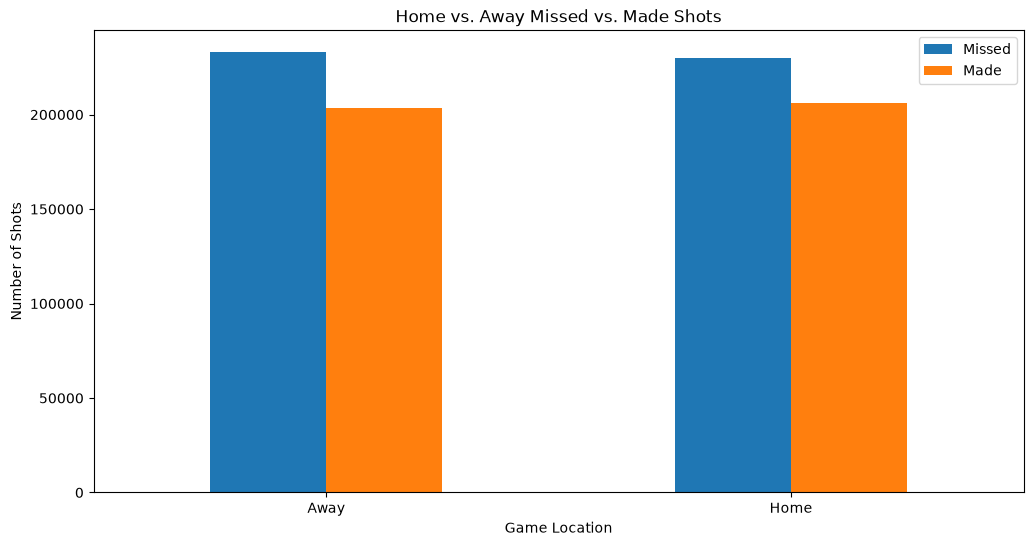

,Missed,Made,Total,FG%
IS_HOME,,,,
Away,232859,203238,436097,46.6
Home,229815,206257,436072,47.3


In [9]:
# create team abbreviation feature
team_abbreviations = {
    "Atlanta Hawks": "ATL",
    "Boston Celtics": "BOS",
    "Brooklyn Nets": "BKN",
    "Charlotte Hornets": "CHA",
    "Chicago Bulls": "CHI",
    "Cleveland Cavaliers": "CLE",
    "Dallas Mavericks": "DAL",
    "Denver Nuggets": "DEN",
    "Detroit Pistons": "DET",
    "Golden State Warriors": "GSW",
    "Houston Rockets": "HOU",
    "Indiana Pacers": "IND",
    "LA Clippers": "LAC",
    "Los Angeles Lakers": "LAL",
    "Memphis Grizzlies": "MEM",
    "Miami Heat": "MIA",
    "Milwaukee Bucks": "MIL",
    "Minnesota Timberwolves": "MIN",
    "New Orleans Pelicans": "NOP",
    "New York Knicks": "NYK",
    "Oklahoma City Thunder": "OKC",
    "Orlando Magic": "ORL",
    "Philadelphia 76ers": "PHI",
    "Phoenix Suns": "PHX",
    "Portland Trail Blazers": "POR",
    "Sacramento Kings": "SAC",
    "San Antonio Spurs": "SAS",
    "Toronto Raptors": "TOR",
    "Utah Jazz": "UTA",
    "Washington Wizards": "WAS"
}

df["TEAM_ABV"] = df["TEAM_NAME"].map(team_abbreviations)

# create new feature for home team
df["IS_HOME"] = np.where(df["TEAM_ABV"] == df["HOME_TEAM"], 1, 0) #if the team name matches the home team, set IS_HOME to 1, otherwise 0

home_stats = df.groupby(["IS_HOME", "MADE"]).size().unstack(fill_value=0)
home_stats.columns = ["Missed", "Made"]
# rename rows
home_stats.rename(index={0: "Away", 1: "Home"}, inplace=True)

home_stats.plot(kind="bar", figsize=(12, 6))

plt.xticks(rotation=0)
plt.xlabel("Game Location")
plt.ylabel("Number of Shots")
plt.title("Home vs. Away Missed vs. Made Shots")
plt.show()

home_stats["Total"] = home_stats["Missed"] + home_stats["Made"]
home_stats["FG%"] = (home_stats["Made"] / home_stats["Total"]) * 100

display(home_stats.round(2))

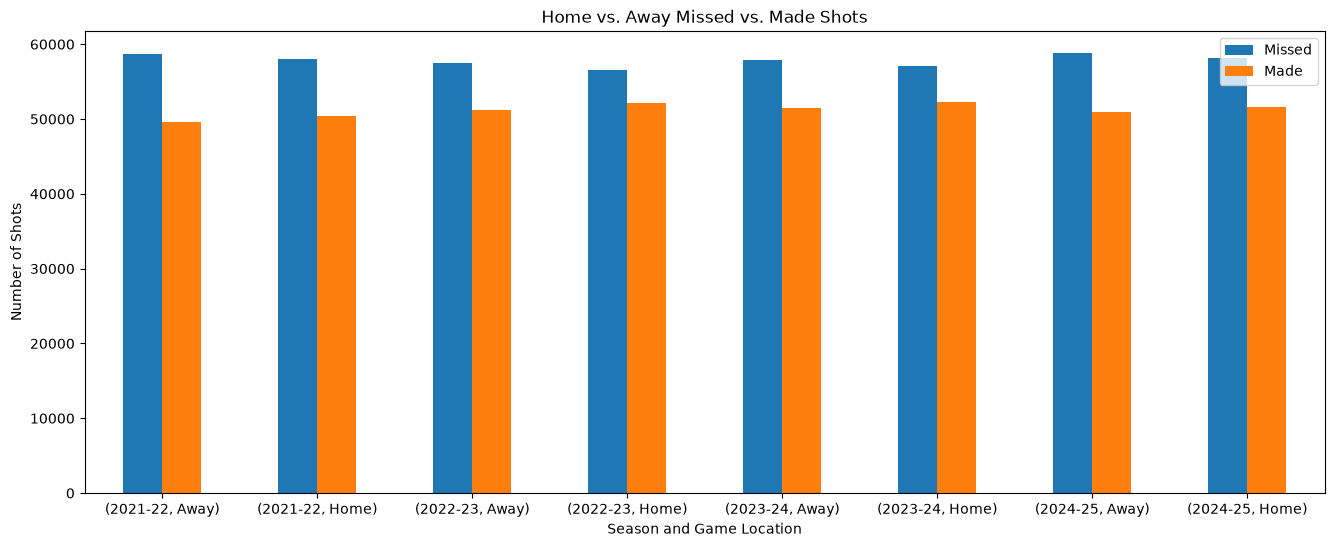

Missed   Made   Total    FG%
SEASON  IS_HOME                              
2021-22 Away      58718  49565  108283  45.77
        Home      58074  50365  108439  46.45
2022-23 Away      57432  51182  108614  47.12
        Home      56528  52078  108606  47.95
2023-24 Away      57890  51506  109396  47.08
        Home      57071  52233  109304  47.79
2024-25 Away      58819  50985  109804  46.43
        Home      58142  51581  109723  47.01

IS_HOME,Away,Home,FG% Difference
SEASON,,,
2021-22,45.77,46.45,0.67
2022-23,47.12,47.95,0.83
2023-24,47.08,47.79,0.70
2024-25,46.43,47.01,0.58


In [10]:
season_home_stats = df.groupby(["SEASON", "IS_HOME", "MADE"]).size().unstack(fill_value=0)
season_home_stats.columns = ["Missed", "Made"]
# rename rows
season_home_stats.rename(index={0: "Away", 1: "Home"}, inplace=True)

season_home_stats.plot(kind="bar", figsize=(16, 6))

plt.xticks(rotation=0)
plt.xlabel("Season and Game Location")
plt.ylabel("Number of Shots")
plt.title("Home vs. Away Missed vs. Made Shots")
plt.show()

season_home_stats["Total"] = season_home_stats["Missed"] + season_home_stats["Made"]
season_home_stats["FG%"] = (season_home_stats["Made"] / season_home_stats["Total"]) * 100

display(season_home_stats.round(2))

fg_comparison = season_home_stats["FG%"].unstack()

fg_comparison["FG% Difference"] = (
    fg_comparison["Home"] - fg_comparison["Away"]
)

display(fg_comparison.round(2))

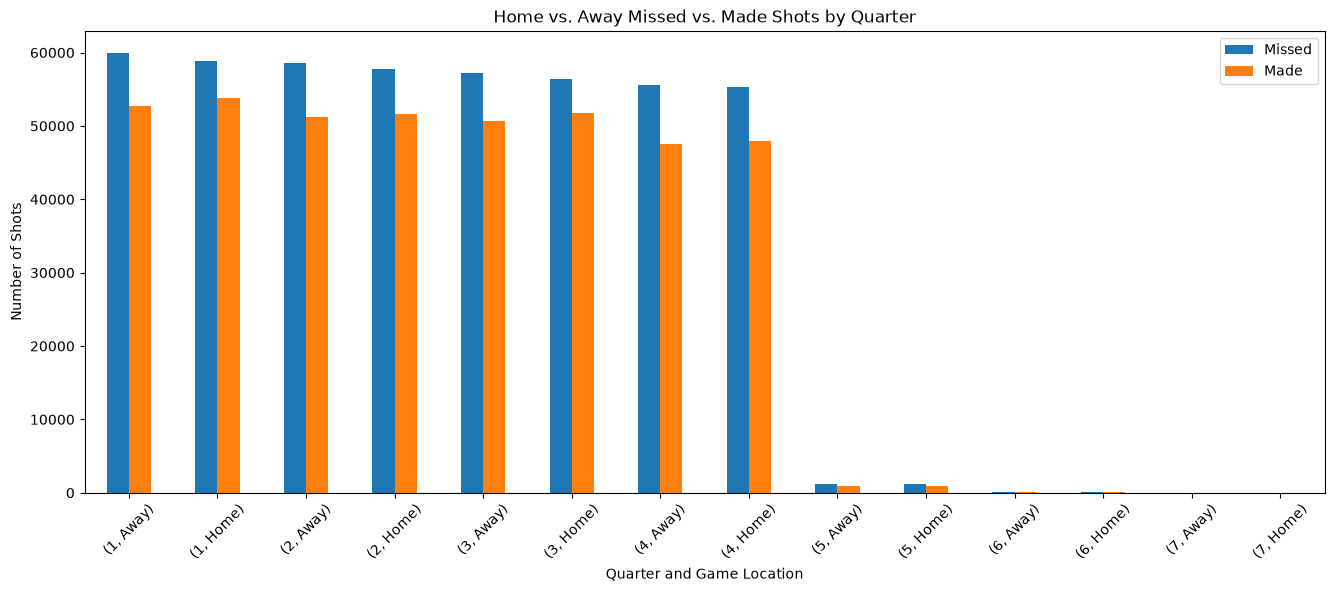

Missed   Made   Total    FG%
QUARTER IS_HOME                              
1       Away      59975  52775  112750  46.81
        Home      58875  53837  112712  47.77
2       Away      58605  51156  109761  46.61
        Home      57706  51647  109353  47.23
3       Away      57222  50705  107927  46.98
        Home      56441  51771  108212  47.84
4       Away      55646  47581  103227  46.09
        Home      55374  47946  103320  46.41
5       Away       1253    922    2175  42.39
        Home       1259    945    2204  42.88
6       Away        152     91     243  37.45
        Home        150    105     255  41.18
7       Away          6      8      14  57.14
        Home         10      6      16  37.50

IS_HOME,Away,Home,FG% Difference
QUARTER,,,
1,46.81,47.77,0.96
2,46.61,47.23,0.62
3,46.98,47.84,0.86
4,46.09,46.41,0.31
5,42.39,42.88,0.49
6,37.45,41.18,3.73
7,57.14,37.50,-19.64


In [11]:
quarter_home_stats = df.groupby(["QUARTER", "IS_HOME", "MADE"]).size().unstack(fill_value=0)
quarter_home_stats.columns = ["Missed", "Made"]
# rename rows
quarter_home_stats.rename(index={0: "Away", 1: "Home"}, level="IS_HOME", inplace=True)

quarter_home_stats.plot(kind="bar", figsize=(16, 6))

plt.xticks(rotation=45)
plt.xlabel("Quarter and Game Location")
plt.ylabel("Number of Shots")
plt.title("Home vs. Away Missed vs. Made Shots by Quarter")
plt.show()

quarter_home_stats["Total"] = quarter_home_stats["Missed"] + quarter_home_stats["Made"]
quarter_home_stats["FG%"] = (quarter_home_stats["Made"] / quarter_home_stats["Total"]) * 100

display(quarter_home_stats.round(2))

fg_comparison = quarter_home_stats["FG%"].unstack()

fg_comparison["FG% Difference"] = (
    fg_comparison["Home"] - fg_comparison["Away"]
)

display(fg_comparison.round(2))

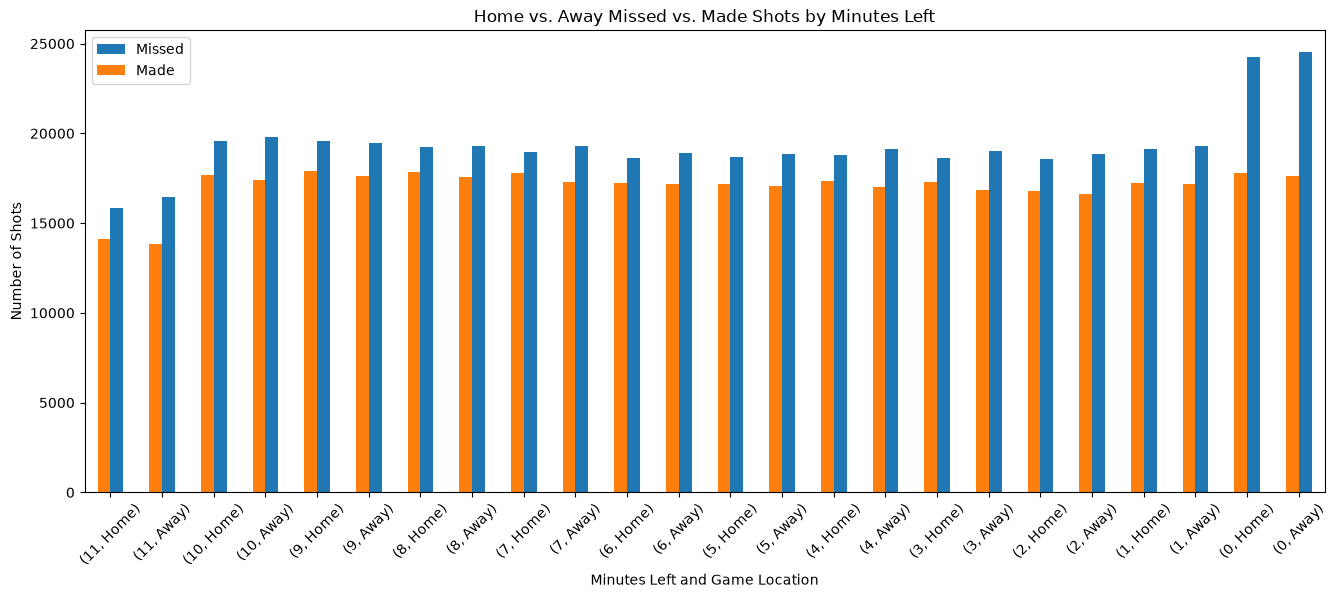

Missed   Made  Total    FG%
MINS_LEFT IS_HOME                             
11        Away      16439  13833  30272  45.70
          Home      15818  14131  29949  47.18
10        Away      19807  17387  37194  46.75
          Home      19574  17672  37246  47.45
9         Away      19442  17641  37083  47.57
          Home      19553  17923  37476  47.83
8         Away      19317  17570  36887  47.63
          Home      19240  17864  37104  48.15
7         Home      18942  17809  36751  48.46
          Away      19307  17277  36584  47.23
6         Home      18649  17213  35862  48.00
          Away      18881  17180  36061  47.64
5         Home      18660  17166  35826  47.91
          Away      18840  17040  35880  47.49
4         Home      18772  17367  36139  48.06
          Away      19116  17002  36118  47.07
3         Home      18630  17299  35929  48.15
          Away      19021  16838  35859  46.96
2         Home      18592  16779  35371  47.44
          Away      18860  16649  35509  46.89
1         Home      19145  17235  36380  47.37
          Away      19318  17178  36496  47.07
0         Home      24240  17799  42039  42.34
          Away      24511  17643  42154  41.85

IS_HOME,Away,Home,FG% Difference
MINS_LEFT,,,
11,45.70,47.18,1.49
10,46.75,47.45,0.70
9,47.57,47.83,0.25
8,47.63,48.15,0.51
7,47.23,48.46,1.23
6,47.64,48.00,0.36
5,47.49,47.91,0.42
4,47.07,48.06,0.98
3,46.96,48.15,1.19


In [12]:
minute_home_stats = df.groupby(["MINS_LEFT", "IS_HOME", "MADE"]).size().unstack(fill_value=0)
minute_home_stats.columns = ["Missed", "Made"]
# rename rows
minute_home_stats.rename(index={0: "Away", 1: "Home"}, level="IS_HOME", inplace=True)

minute_home_stats.plot(kind="bar", figsize=(16, 6))
# reverse row values for the table
minute_home_stats = minute_home_stats.sort_values(["MINS_LEFT"], ascending=[False])

plt.xticks(rotation=45)
# reverse x axis order
plt.gca().invert_xaxis()
plt.xlabel("Minutes Left and Game Location")
plt.ylabel("Number of Shots")
plt.title("Home vs. Away Missed vs. Made Shots by Minutes Left")
plt.show()

minute_home_stats["Total"] = minute_home_stats["Missed"] + minute_home_stats["Made"]
minute_home_stats["FG%"] = (minute_home_stats["Made"] / minute_home_stats["Total"]) * 100

display(minute_home_stats.round(2))

fg_comparison = minute_home_stats["FG%"].unstack()
# reverse row values for the table
fg_comparison = fg_comparison.sort_values(["MINS_LEFT"], ascending=[False])

fg_comparison["FG% Difference"] = (
    fg_comparison["Home"] - fg_comparison["Away"]
)

display(fg_comparison.round(2))

To answer the question, it seems like home court is an advantage in terms of fg%. Across all seasons, quarters, minutes, and comparing home team fg% with away team fg%, the home team always shoots better. The fg% difference is small, however, it wouldn't be bad to include it into our model since it does have some effect.

# Are Some Arenas Harder to Play In? - Home vs. Away Field Goal Percentage by Location

In [13]:
team_home_stats = df.groupby(["HOME_TEAM", "IS_HOME", "MADE"]).size().unstack(fill_value=0)

team_home_stats.columns = ["Missed", "Made"]
team_home_stats.rename(index={0: "Away", 1: "Home"}, level="IS_HOME", inplace=True)

team_home_stats["Total"] = team_home_stats["Missed"] + team_home_stats["Made"]
team_home_stats["FG%"] = (team_home_stats["Made"] / team_home_stats["Total"]) * 100

display(team_home_stats.round(2))

home_fg_comparison = team_home_stats["FG%"].unstack()

home_fg_comparison["FG% Difference"] = (
    home_fg_comparison["Home"] - home_fg_comparison["Away"]
)

display(home_fg_comparison.round(2))

Missed  Made  Total    FG%
HOME_TEAM IS_HOME                            
ATL       Away       7680  7137  14817  48.17
          Home       7749  7140  14889  47.95
BKN       Away       7709  6696  14405  46.48
          Home       7713  6618  14331  46.18
BOS       Away       8158  6608  14766  44.75
          Home       7627  6984  14611  47.80
CHA       Away       7744  6882  14626  47.05
          Home       7963  6633  14596  45.44
CHI       Away       7807  6859  14666  46.77
          Home       7649  6979  14628  47.71
CLE       Away       7772  6526  14298  45.64
          Home       7370  6941  14311  48.50
DAL       Away       7677  6645  14322  46.40
          Home       7472  6702  14174  47.28
DEN       Away       7794  6767  14561  46.47
          Home       7175  7264  14439  50.31
DET       Away       7544  6809  14353  47.44
          Home       7777  6594  14371  45.88
GSW       Away       7990  6622  14612  45.32
          Home       7850  6928  14778  46.88
HOU       Away       7833  6743  14576  46.26
          Home       7974  6778  14752  45.95
IND       Away       7533  7074  14607  48.43
          Home       7554  7264  14818  49.02
LAC       Away       7776  6654  14430  46.11
          Home       7384  6831  14215  48.05
LAL       Away       8130  6954  15084  46.10
          Home       7419  7025  14444  48.64
MEM       Away       7946  6653  14599  45.57
          Home       7996  7098  15094  47.03
MIA       Away       7351  6573  13924  47.21
          Home       7367  6639  14006  47.40
MIL       Away       8321  6901  15222  45.34
          Home       7651  7118  14769  48.20
MIN       Away       7958  6488  14446  44.91
          Home       7551  6766  14317  47.26
NOP       Away       7571  6686  14257  46.90
          Home       7676  6780  14456  46.90
NYK       Away       7644  6578  14222  46.25
          Home       7719  6753  14472  46.66
OKC       Away       7949  6619  14568  45.44
          Home       7851  7201  15052  47.84
ORL       Away       7430  6444  13874  46.45
          Home       7581  6530  14111  46.28
PHI       Away       7580  6672  14252  46.81
          Home       7645  6613  14258  46.38
PHX       Away       7943  6656  14599  45.59
          Home       7484  6919  14403  48.04
POR       Away       7351  6911  14262  48.46
          Home       7907  6579  14486  45.42
SAC       Away       7475  7004  14479  48.37
          Home       7487  7009  14496  48.35
SAS       Away       7771  7288  15059  48.40
          Home       7832  7054  14886  47.39
TOR       Away       7498  6695  14193  47.17
          Home       8023  6852  14875  46.06
UTA       Away       8065  6957  15022  46.31
          Home       7683  6834  14517  47.08
WAS       Away       7859  7137  14996  47.59
          Home       7686  6831  14517  47.06

IS_HOME,Away,Home,FG% Difference
HOME_TEAM,,,
ATL,48.17,47.95,-0.21
BKN,46.48,46.18,-0.30
BOS,44.75,47.80,3.05
CHA,47.05,45.44,-1.61
CHI,46.77,47.71,0.94
CLE,45.64,48.50,2.86
DAL,46.40,47.28,0.89
DEN,46.47,50.31,3.83
DET,47.44,45.88,-1.56


One problem with analyzing the field goal percentage difference between the home team and the visiting team at every arena to determine which arenas are harder for the visiting team is that how good the team is offensively and defensively could contribute to the difference. If a team is very good offensively, their home field goal percentage would naturally be higher, similarly, if a team is very bad offensively, their home field goal percentage would be lower. Using the same logic, a bad defensive team would allow away teams a higher field goal percentage, and a good defensive team would allow a lower field goal percentage. In summary, the field goal percentage difference cannot conclusively tell if one arena is harder to play (for the away team) in without considering the context.

However, we can compare the team field goal percentage away to the field goal percentage when playing at home to see if teams get an offensive boost while playing at home.

In [14]:
away_stats = df[df["IS_HOME"] == 0].groupby(["TEAM_ABV", "MADE"]).size().unstack(fill_value=0)
away_stats.columns = ["Missed", "Made"]

away_stats["Total (away)"] = away_stats["Missed"] + away_stats["Made"]
away_stats["Away FG%"] = (away_stats["Made"] / away_stats["Total (away)"]) * 100

away_stats["Home FG%"] = home_fg_comparison["Home"]
away_stats["FG% Difference"] = away_stats["Home FG%"] - away_stats["Away FG%"]

display(away_stats.round(2))

,Missed,Made,Total (away),Away FG%,Home FG%,FG% Difference
TEAM_ABV,,,,,,
ATL,8034,7004,15038,46.58,47.95,1.38
BKN,7622,6643,14265,46.57,46.18,-0.39
BOS,7781,6831,14612,46.75,47.80,1.05
CHA,8072,6683,14755,45.29,45.44,0.15
CHI,7577,6922,14499,47.74,47.71,-0.03
CLE,7405,6799,14204,47.87,48.50,0.63
DAL,7482,6781,14263,47.54,47.28,-0.26
DEN,7307,7060,14367,49.14,50.31,1.17
DET,8000,6635,14635,45.34,45.88,0.55


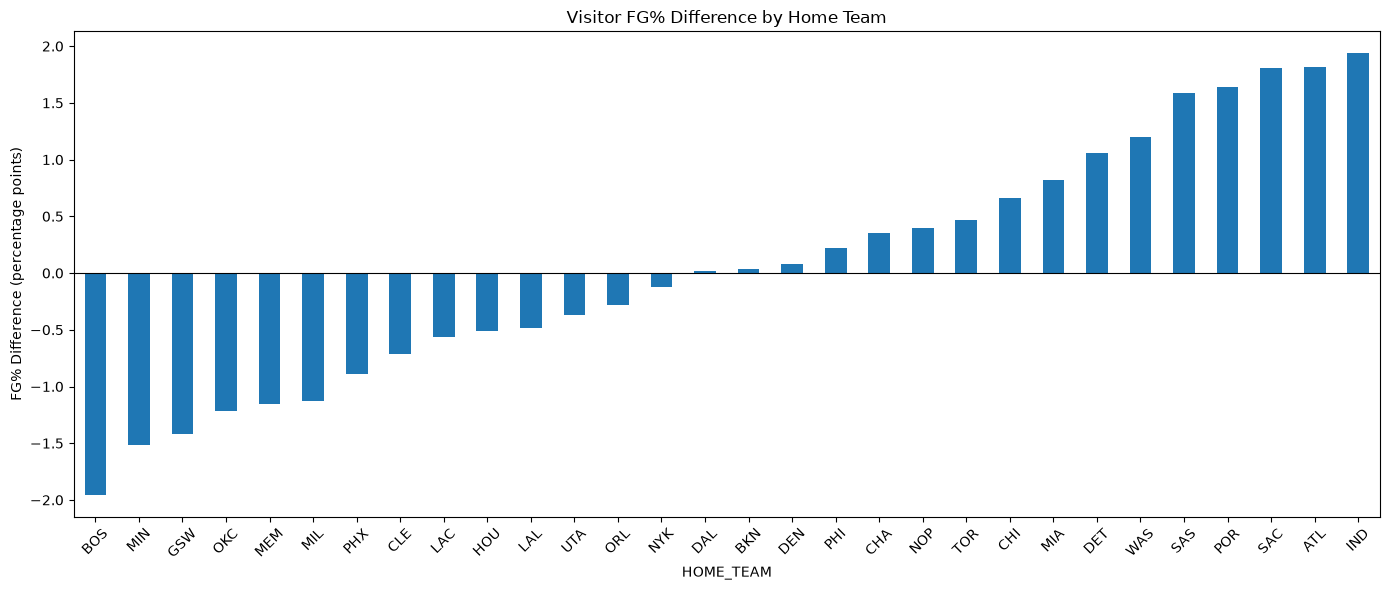

HOME_TEAM
BOS   -1.96
MIN   -1.52
GSW   -1.42
OKC   -1.22
MEM   -1.15
MIL   -1.13
PHX   -0.89
CLE   -0.71
LAC   -0.57
HOU   -0.51
LAL   -0.48
UTA   -0.37
ORL   -0.28
NYK   -0.13
DAL    0.02
BKN    0.03
DEN    0.08
PHI    0.22
CHA    0.35
NOP    0.40
TOR    0.47
CHI    0.66
MIA    0.82
DET    1.06
WAS    1.20
SAS    1.59
POR    1.64
SAC    1.81
ATL    1.82
IND    1.94
dtype: float64

In [15]:
visitor_stats = df[df["IS_HOME"] == 0].groupby(["TEAM_ABV", "HOME_TEAM", "MADE"]).size().unstack(fill_value=0)

# fg% when playing away at another team
visitor_stats["FG%"] = (visitor_stats[1] / (visitor_stats[0] + visitor_stats[1])) * 100

away_avg = df[df["IS_HOME"] == 0].groupby(["TEAM_ABV", "MADE"]).size().unstack(fill_value=0)

# average fg% when playing away
away_avg.columns = ["Missed", "Made"]
away_avg["Total"] = away_avg["Made"] + away_avg["Missed"]
away_avg["FG%"] = (away_avg["Made"] / away_avg["Total"]) * 100

visitor_comparison = visitor_stats["FG%"].unstack(level="HOME_TEAM")

visitor_difference = visitor_comparison.sub(away_avg["FG%"], axis=0)
arena_effect = visitor_difference.mean().sort_values()

arena_effect.plot(kind="bar", figsize=(14, 6), title="Visitor FG% Difference by Home Team")

plt.axhline(0, color="black", linewidth=0.8)
plt.ylabel("FG% Difference (percentage points)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

display(arena_effect.round(2))

This graph is meant to represent how much worse (or better) a visiting team shoots in a particular arena. This is calculated by subtracting the fg% visiting teams shoot in a particular arena from the fg% they shoot when playing as the away team in general for every team in the NBA. The arena effect is the average of this fg% disparity. A lower arena effect is better.

One criticism of this could be that it doesn't account for team defense which partially contributes to the fg% difference as the higher scoring teams all have above average defensive ratings. However, it is not entirely correlated with team defense as MIA has a very good defensive rating but scores very low. Additionally, the bottom 8 teams with the exception of POR have around average defensive ratings. Similarly, PHX is scored very high, but the team defensive rating is only slightly better than average.

In [16]:
combined_stats = pd.DataFrame({
    "FG% Difference": away_stats["FG% Difference"],
    "Arena Effect": arena_effect
})

combined_stats["Combined Advantage"] = (
    combined_stats["FG% Difference"] - combined_stats["Arena Effect"]
)

display(combined_stats.round(2))

,FG% Difference,Arena Effect,Combined Advantage
ATL,1.38,1.82,-0.44
BKN,-0.39,0.03,-0.42
BOS,1.05,-1.96,3.01
CHA,0.15,0.35,-0.20
CHI,-0.03,0.66,-0.69
CLE,0.63,-0.71,1.35
DAL,-0.26,0.02,-0.28
DEN,1.17,0.08,1.09
DET,0.55,1.06,-0.51
GSW,0.01,-1.42,1.42


This table displays the fg% advantage every team gets by playing at home. There are a couple of teams that benefit heavily from playing at home. Although this statistic is influenced by team quality, it is still worth examining because team quality is itself a factor that affects FG.